# Level 2 — Task 3: Feature Engineering

**Cognifyz Technologies — Data Science Internship**

## Introduction
Raw columns are not always the most useful inputs for analysis or modelling. **Feature engineering** creates new, informative columns from existing ones. In this notebook we derive text-length features, binary service indicators and a cuisine count from the restaurant dataset, validate them, explore their distributions and export an engineered copy of the data.

## Objectives
1. Create `Restaurant Name Length` and `Address Length`.
2. Create binary features `Has Table Booking` and `Has Online Delivery` (Yes → 1, No → 0, unknown → missing).
3. Create `Cuisine Count` from the comma-separated `Cuisines` column.
4. Add a few extra, clearly explained features that do not leak target information.
5. Compare original and engineered columns, describe and visualise the new features, and run automatic validation checks.
6. Export the engineered dataset to `../Dataset/engineered_restaurant_data.csv` (the original `Dataset.csv` is never modified).

> **No predictive modelling is done here, and no feature is built from `Aggregate rating`, `Rating color`, `Rating text` or `Votes`** (outcome-related columns), which avoids data leakage into any later model.

## 1. Imports and Notebook Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)

# Consistent styling for every chart in this notebook
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({
    "figure.figsize": (10, 5.5),
    "figure.dpi": 100,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "legend.frameon": True,
})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)


def show_table(table, title):
    """Display a DataFrame with a bold title above it."""
    display(Markdown(f"**{title}**"))
    display(table)


def show_findings(findings):
    """Render a list of strings as a Markdown bullet list."""
    display(Markdown("\n".join(f"- {item}" for item in findings)))

## 2. Load the Original Dataset
The original file is read from `../dataset/Dataset.csv` (run this notebook from the `Level2` folder). It is loaded into `df` and **left untouched**; all new columns are added to a separate copy called `engineered`.

In [2]:
DATA_PATH = Path("../dataset/Dataset.csv")   # notebook is run from the Level2 folder
REQUIRED_COLUMNS = ["Restaurant Name", "Address", "Cuisines", "Has Table booking", "Has Online delivery"]

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset not found at '{DATA_PATH}' (looked in: {DATA_PATH.resolve()}). "
        "Run this notebook from the 'Level2' folder and make sure 'Dataset/Dataset.csv' exists."
    )

try:
    df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
except UnicodeDecodeError:
    df = pd.read_csv(DATA_PATH, encoding="latin-1")

df.columns = df.columns.str.strip()

missing_columns = [col for col in REQUIRED_COLUMNS if col not in df.columns]
if missing_columns:
    raise KeyError(f"Required column(s) missing from the dataset: {missing_columns}")

print(f"Loaded '{DATA_PATH}' successfully: {df.shape[0]:,} rows x {df.shape[1]} columns")
display(df.head())

Loaded '..\dataset\Dataset.csv' successfully: 9,551 rows x 21 columns


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,Average Cost for two,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.03,14.57,"French, Japanese, Desserts",1100,Botswana Pula(P),Yes,No,No,No,3,4.80,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.01,14.55,Japanese,1200,Botswana Pula(P),Yes,No,No,No,3,4.50,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.06,14.58,"Seafood, Asian, Filipino, Indian",4000,Botswana Pula(P),Yes,No,No,No,4,4.40,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.06,14.59,"Japanese, Sushi",1500,Botswana Pula(P),No,No,No,No,4,4.90,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.06,14.58,"Japanese, Korean",1500,Botswana Pula(P),Yes,No,No,No,4,4.80,Dark Green,Excellent,229


## 3. Inspect the Relevant Columns
We check data types and missing values for the columns the new features will be built from.

In [3]:
source_columns = ["Restaurant Name", "Address", "Cuisines", "Has Table booking", "Has Online delivery"]

inspection = pd.DataFrame({
    "Data Type": df[source_columns].dtypes.astype(str),
    "Missing Values": df[source_columns].isna().sum(),
    "Missing (%)": df[source_columns].isna().mean() * 100,
    "Distinct Values": df[source_columns].nunique(dropna=True),
})
inspection.index.name = "Source column"
show_table(inspection, "Source columns used for feature engineering")

blank_cuisines = int(df["Cuisines"].astype("string").str.strip().eq("").sum())
print(f"Blank (empty-string) Cuisines values: {blank_cuisines:,}")
for column in ["Has Table booking", "Has Online delivery"]:
    print(f"{column}: {sorted(df[column].dropna().astype(str).unique().tolist())}")

**Source columns used for feature engineering**

,Data Type,Missing Values,Missing (%),Distinct Values
Source column,,,,
Restaurant Name,str,0,0.00,7446
Address,str,0,0.00,8918
Cuisines,str,9,0.09,1825
Has Table booking,str,0,0.00,2
Has Online delivery,str,0,0.00,2


Blank (empty-string) Cuisines values: 0
Has Table booking: ['No', 'Yes']
Has Online delivery: ['No', 'Yes']


## 4. Create the New Features
### Conventions used
| Feature | Rule |
|---|---|
| `Restaurant Name Length` | Number of characters in `Restaurant Name` (spaces and punctuation included). |
| `Address Length` | Number of characters in `Address`. |
| `Has Table Booking` | `Yes` → 1, `No` → 0. Missing or unrecognised → **missing** (not 0). |
| `Has Online Delivery` | `Yes` → 1, `No` → 0. Missing or unrecognised → **missing** (not 0). |
| `Cuisine Count` | Number of **distinct** cuisines in the comma-separated `Cuisines` text (case-insensitive, extra spaces and empty items ignored). A missing or blank `Cuisines` value gives a **missing** count rather than 0, because "no information" is not the same as "zero cuisines"; this keeps the missing-value convention the same as the binary features. |

The binary and count features use pandas' nullable integer type (`Int64`) so that missing values can be preserved.

In [4]:
def normalize_yes_no(series):
    """Return a Series containing only 'Yes', 'No' or NaN.

    Whitespace and capitalisation are ignored ('yes ', 'YES' -> 'Yes').
    Missing or unrecognised values stay NaN - they are NOT treated as 'No'.
    """
    cleaned = series.astype("string").str.strip().str.lower()
    is_yes = cleaned.eq("yes").fillna(False).to_numpy(dtype=bool)
    is_no = cleaned.eq("no").fillna(False).to_numpy(dtype=bool)
    result = pd.Series(np.nan, index=series.index, dtype=object)
    result[is_yes] = "Yes"
    result[is_no] = "No"
    return result


def report_unexpected(series, column_name):
    """Print how many values are missing or not recognised as Yes/No."""
    cleaned = series.astype("string").str.strip().str.lower()
    n_missing = int(series.isna().sum())
    n_unexpected = int((cleaned.notna() & ~cleaned.isin(["yes", "no"])).sum())
    print(f"{column_name:<22} missing: {n_missing:>5,} | unexpected (not Yes/No): {n_unexpected:>5,}")
    if n_unexpected:
        print("   unexpected values:", sorted(cleaned[cleaned.notna() & ~cleaned.isin(['yes', 'no'])].unique()))


engineered = df.copy()          # the original df stays untouched

# --- Text-length features ---------------------------------------------------
engineered["Restaurant Name Length"] = engineered["Restaurant Name"].astype("string").str.len().astype("Int64")
engineered["Address Length"] = engineered["Address"].astype("string").str.len().astype("Int64")

# --- Binary features (Yes -> 1, No -> 0, unknown stays missing) --------------
report_unexpected(df["Has Table booking"], "Has Table booking")
report_unexpected(df["Has Online delivery"], "Has Online delivery")
binary_map = {"Yes": 1, "No": 0}
engineered["Has Table Booking"] = normalize_yes_no(df["Has Table booking"]).map(binary_map).astype("Int64")
engineered["Has Online Delivery"] = normalize_yes_no(df["Has Online delivery"]).map(binary_map).astype("Int64")


# --- Cuisine Count ------------------------------------------------------------
def count_cuisines(value):
    """Number of distinct cuisines in a comma-separated string; missing/blank -> NA."""
    if pd.isna(value):
        return pd.NA
    items = {item.strip().lower() for item in str(value).split(",") if item.strip()}
    return len(items) if items else pd.NA


engineered["Cuisine Count"] = engineered["Cuisines"].apply(count_cuisines).astype("Int64")

core_features = ["Restaurant Name Length", "Address Length", "Has Table Booking", "Has Online Delivery", "Cuisine Count"]
print("Core features created:", core_features)

Has Table booking      missing:     0 | unexpected (not Yes/No):     0
Has Online delivery    missing:     0 | unexpected (not Yes/No):     0
Core features created: ['Restaurant Name Length', 'Address Length', 'Has Table Booking', 'Has Online Delivery', 'Cuisine Count']


### Additional features (optional)
Four extra features built only from descriptive columns (name, address, cuisines and the two service flags):

* `Restaurant Name Word Count` – number of words in the name.
* `Address Word Count` – number of words in the address.
* `Is Multi Cuisine` – 1 if the restaurant lists more than one cuisine, 0 if exactly one; missing if `Cuisine Count` is missing.
* `Services Offered Count` – how many of the two services (table booking, online delivery) the restaurant offers (0, 1 or 2); missing if either flag is unknown.

None of them uses `Aggregate rating`, `Rating color`, `Rating text` or `Votes`, and the original columns are not changed.

In [5]:
engineered["Restaurant Name Word Count"] = engineered["Restaurant Name"].astype("string").str.split().str.len().astype("Int64")
engineered["Address Word Count"] = engineered["Address"].astype("string").str.split().str.len().astype("Int64")

is_multi = (engineered["Cuisine Count"] > 1).astype("Int64")
is_multi[engineered["Cuisine Count"].isna()] = pd.NA
engineered["Is Multi Cuisine"] = is_multi

engineered["Services Offered Count"] = (engineered["Has Table Booking"] + engineered["Has Online Delivery"]).astype("Int64")

extra_features = ["Restaurant Name Word Count", "Address Word Count", "Is Multi Cuisine", "Services Offered Count"]
new_features = core_features + extra_features
print(f"Total new features: {len(new_features)}")
print(f"Engineered dataset shape: {engineered.shape[0]:,} rows x {engineered.shape[1]} columns "
      f"(original had {df.shape[1]} columns)")

Total new features: 9
Engineered dataset shape: 9,551 rows x 30 columns (original had 21 columns)


## 5. Compare Original and Engineered Columns
First a mapping of every source column to the feature(s) derived from it, then a side-by-side preview of original values and engineered values. (Note that the original column is `Has Table booking` with a lowercase "b", while the new feature is `Has Table Booking`.)

In [6]:
feature_map = pd.DataFrame([
    ("Restaurant Name", "Restaurant Name Length", "Character count"),
    ("Restaurant Name", "Restaurant Name Word Count", "Word count"),
    ("Address", "Address Length", "Character count"),
    ("Address", "Address Word Count", "Word count"),
    ("Has Table booking", "Has Table Booking", "Yes -> 1, No -> 0, unknown -> missing"),
    ("Has Online delivery", "Has Online Delivery", "Yes -> 1, No -> 0, unknown -> missing"),
    ("Cuisines", "Cuisine Count", "Distinct comma-separated cuisines; blank -> missing"),
    ("Cuisines", "Is Multi Cuisine", "Cuisine Count > 1"),
    ("Has Table booking + Has Online delivery", "Services Offered Count", "Sum of the two binary flags"),
], columns=["Original column(s)", "Engineered feature", "Rule"])
feature_map["Missing values in feature"] = [int(engineered[name].isna().sum()) for name in feature_map["Engineered feature"]]
show_table(feature_map, "Original columns and the features engineered from them")

comparison_columns = ["Restaurant Name", "Restaurant Name Length", "Address", "Address Length",
                      "Cuisines", "Cuisine Count", "Has Table booking", "Has Table Booking",
                      "Has Online delivery", "Has Online Delivery"]
show_table(engineered[comparison_columns].head(10), "Original vs engineered values (first 10 rows)")

**Original columns and the features engineered from them**

,Original column(s),Engineered feature,Rule,Missing values in feature
0,Restaurant Name,Restaurant Name Length,Character count,0
1,Restaurant Name,Restaurant Name Word Count,Word count,0
2,Address,Address Length,Character count,0
3,Address,Address Word Count,Word count,0
4,Has Table booking,Has Table Booking,"Yes -> 1, No -> 0, unknown -> missing",0
5,Has Online delivery,Has Online Delivery,"Yes -> 1, No -> 0, unknown -> missing",0
6,Cuisines,Cuisine Count,Distinct comma-separated cuisines; blank -> mi...,9
7,Cuisines,Is Multi Cuisine,Cuisine Count > 1,9
8,Has Table booking + Has Online delivery,Services Offered Count,Sum of the two binary flags,0


**Original vs engineered values (first 10 rows)**

,Restaurant Name,Restaurant Name Length,Address,Address Length,Cuisines,Cuisine Count,Has Table booking,Has Table Booking,Has Online delivery,Has Online Delivery
0,Le Petit Souffle,16,"Third Floor, Century City Mall, Kalayaan Avenu...",71,"French, Japanese, Desserts",3,Yes,1,No,0
1,Izakaya Kikufuji,16,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...",67,Japanese,1,Yes,1,No,0
2,Heat - Edsa Shangri-La,22,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...",56,"Seafood, Asian, Filipino, Indian",4,Yes,1,No,0
3,Ooma,4,"Third Floor, Mega Fashion Hall, SM Megamall, O...",70,"Japanese, Sushi",2,No,0,No,0
4,Sambo Kojin,11,"Third Floor, Mega Atrium, SM Megamall, Ortigas...",64,"Japanese, Korean",2,Yes,1,No,0
5,Din Tai Fung,12,"Ground Floor, Mega Fashion Hall, SM Megamall, ...",71,Chinese,1,No,0,No,0
6,Buffet 101,10,"Building K, SM By The Bay, Sunset Boulevard, M...",83,"Asian, European",2,Yes,1,No,0
7,Vikings,7,"Building B, By The Bay, Seaside Boulevard, Mal...",81,"Seafood, Filipino, Asian, European",4,Yes,1,No,0
8,Spiral - Sofitel Philippine Plaza Manila,40,"Plaza Level, Sofitel Philippine Plaza Manila, ...",69,"European, Asian, Indian",3,Yes,1,No,0
9,Locavore,8,"Brixton Technology Center, 10 Brixton Street, ...",67,Filipino,1,Yes,1,No,0


## 6. Descriptive Statistics of the New Features
Count, mean, spread and quartiles for each engineered feature, plus how many values are missing.

In [7]:
feature_stats = engineered[new_features].astype("Float64").describe().T
feature_stats.insert(0, "Missing", engineered[new_features].isna().sum())
feature_stats.index.name = "Feature"
show_table(feature_stats, "Descriptive statistics of engineered features")

binary_features = ["Has Table Booking", "Has Online Delivery", "Is Multi Cuisine"]
binary_table = pd.DataFrame({
    feature: engineered[feature].value_counts(dropna=False).rename({0: "0 (No)", 1: "1 (Yes)", pd.NA: "Missing"})
    for feature in binary_features
}).fillna(0).astype(int)
binary_table.index.name = "Value"
show_table(binary_table, "Value counts of the binary features")

**Descriptive statistics of engineered features**

,Missing,count,mean,std,min,25%,50%,75%,max
Feature,,,,,,,,,
Restaurant Name Length,0,"9,551.00",15.16,6.86,2.00,10.00,14.00,19.00,54.00
Address Length,0,"9,551.00",53.54,17.12,13.00,41.00,52.00,64.00,132.00
Has Table Booking,0,"9,551.00",0.12,0.33,0.00,0.00,0.00,0.00,1.00
Has Online Delivery,0,"9,551.00",0.26,0.44,0.00,0.00,0.00,1.00,1.00
Cuisine Count,9,"9,542.00",2.07,1.09,1.00,1.00,2.00,3.00,8.00
Restaurant Name Word Count,0,"9,551.00",2.57,1.24,1.00,2.00,2.00,3.00,10.00
Address Word Count,0,"9,551.00",8.74,2.63,2.00,7.00,8.00,10.00,20.00
Is Multi Cuisine,9,"9,542.00",0.64,0.48,0.00,0.00,1.00,1.00,1.00
Services Offered Count,0,"9,551.00",0.38,0.57,0.00,0.00,0.00,1.00,2.00


**Value counts of the binary features**

,Has Table Booking,Has Online Delivery,Is Multi Cuisine
Value,,,
0 (No),8393,7100,3394
1 (Yes),1158,2451,6148
Missing,0,0,9


## 7. Visualise the Engineered Features
### 7.1 Distributions

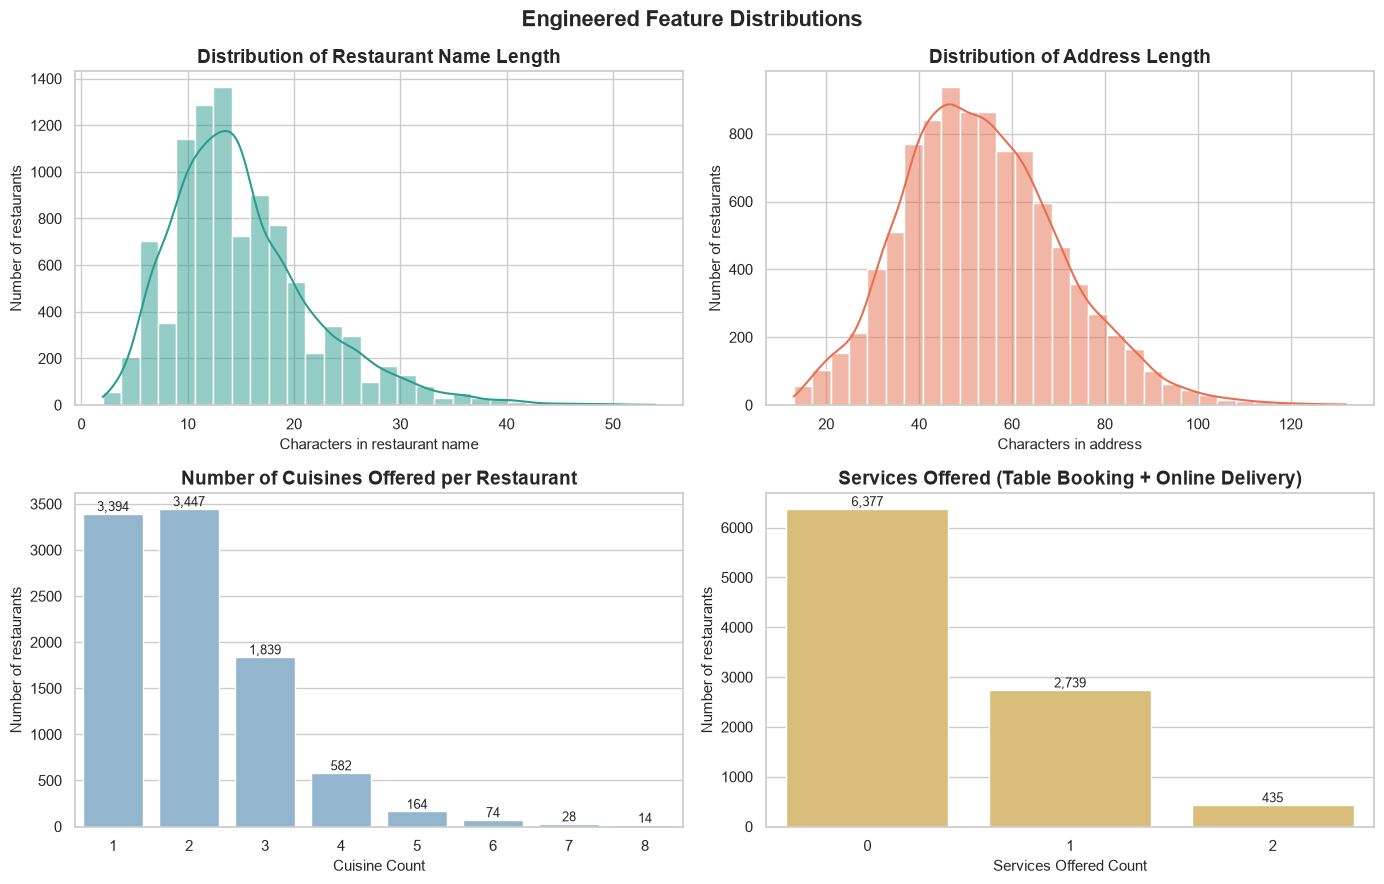

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.histplot(engineered["Restaurant Name Length"].dropna().astype(float), bins=30, kde=True, color="#2a9d8f", ax=axes[0, 0])
axes[0, 0].set_title("Distribution of Restaurant Name Length")
axes[0, 0].set_xlabel("Characters in restaurant name")
axes[0, 0].set_ylabel("Number of restaurants")

sns.histplot(engineered["Address Length"].dropna().astype(float), bins=30, kde=True, color="#e76f51", ax=axes[0, 1])
axes[0, 1].set_title("Distribution of Address Length")
axes[0, 1].set_xlabel("Characters in address")
axes[0, 1].set_ylabel("Number of restaurants")

cuisine_counts = engineered["Cuisine Count"].dropna().astype(int).value_counts().sort_index()
sns.barplot(x=cuisine_counts.index.astype(str), y=cuisine_counts.values, color="#8ab6d6", ax=axes[1, 0])
for position, value in enumerate(cuisine_counts.values):
    axes[1, 0].text(position, value, f"{value:,}", ha="center", va="bottom", fontsize=9)
axes[1, 0].set_title("Number of Cuisines Offered per Restaurant")
axes[1, 0].set_xlabel("Cuisine Count")
axes[1, 0].set_ylabel("Number of restaurants")

services = engineered["Services Offered Count"].dropna().astype(int).value_counts().sort_index()
sns.barplot(x=services.index.astype(str), y=services.values, color="#e9c46a", ax=axes[1, 1])
for position, value in enumerate(services.values):
    axes[1, 1].text(position, value, f"{value:,}", ha="center", va="bottom", fontsize=9)
axes[1, 1].set_title("Services Offered (Table Booking + Online Delivery)")
axes[1, 1].set_xlabel("Services Offered Count")
axes[1, 1].set_ylabel("Number of restaurants")

fig.suptitle("Engineered Feature Distributions", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

### 7.2 Relationships between features
Here `Aggregate rating` is used **only to explore** how the new features relate to ratings; it is not used to build any feature. Unrated restaurants (rating 0) are left out of rating comparisons. Cuisine counts of 6 or more are grouped as "6+" for readability (this grouping exists only for the chart and is not saved).

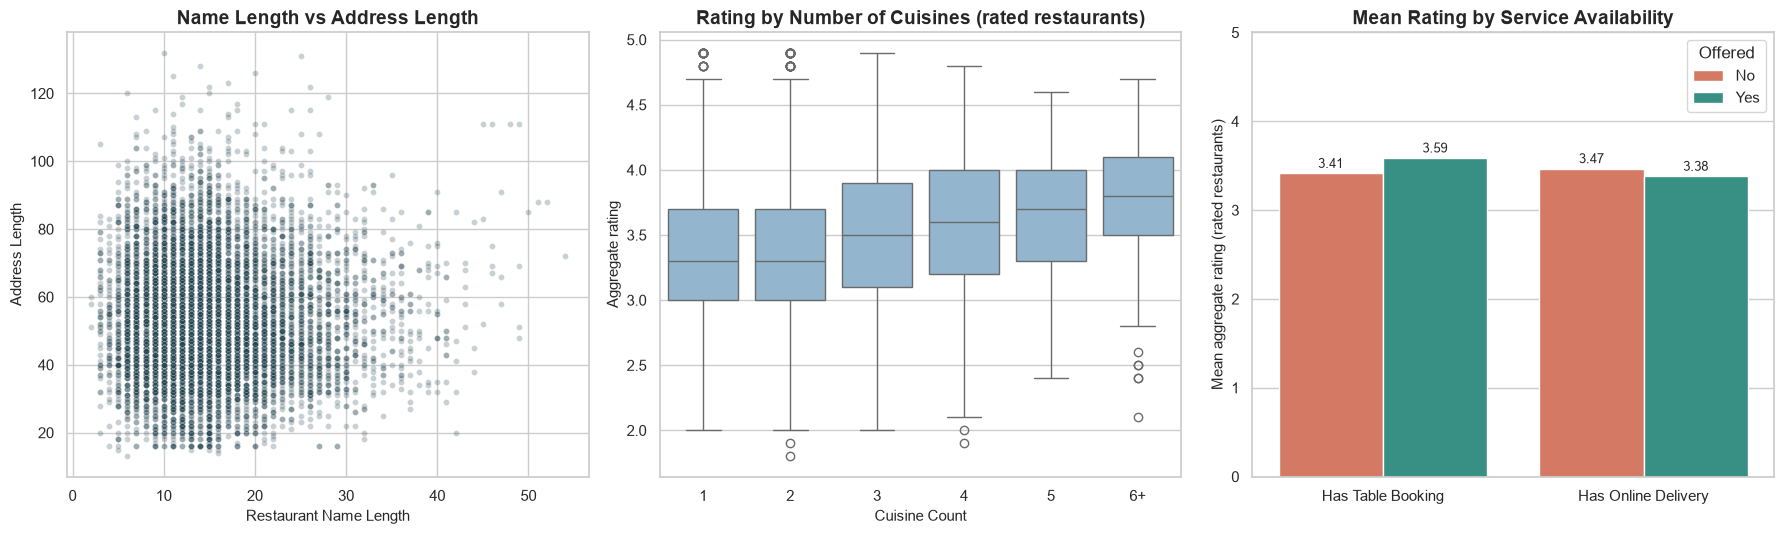

In [9]:
plot_df = engineered.copy()
plot_df["Aggregate rating"] = pd.to_numeric(plot_df["Aggregate rating"], errors="coerce")
rated_plot = plot_df[plot_df["Aggregate rating"] > 0].copy()

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# (a) name length vs address length
sample = plot_df.dropna(subset=["Restaurant Name Length", "Address Length"])
sns.scatterplot(x=sample["Restaurant Name Length"].astype(float), y=sample["Address Length"].astype(float),
                alpha=0.25, s=18, color="#264653", ax=axes[0])
axes[0].set_title("Name Length vs Address Length")
axes[0].set_xlabel("Restaurant Name Length")
axes[0].set_ylabel("Address Length")

# (b) rating by cuisine count group
group_source = rated_plot.dropna(subset=["Cuisine Count"]).copy()
cuisine_numeric = group_source["Cuisine Count"].astype(int).clip(upper=6)
group_source["Cuisine Count Group"] = cuisine_numeric.astype(str).replace({"6": "6+"})
group_order = sorted(group_source["Cuisine Count Group"].unique(), key=lambda g: int(g.replace("+", "")))
sns.boxplot(data=group_source, x="Cuisine Count Group", y="Aggregate rating", order=group_order,
            color="#8ab6d6", ax=axes[1])
axes[1].set_title("Rating by Number of Cuisines (rated restaurants)")
axes[1].set_xlabel("Cuisine Count")
axes[1].set_ylabel("Aggregate rating")

# (c) mean rating by service flags
service_rows = []
for feature in ["Has Table Booking", "Has Online Delivery"]:
    for value, label in [(0, "No"), (1, "Yes")]:
        subset = rated_plot[rated_plot[feature] == value]["Aggregate rating"]
        if len(subset):
            service_rows.append({"Feature": feature, "Offered": label, "Mean Rating": subset.mean()})
service_means = pd.DataFrame(service_rows)
sns.barplot(data=service_means, x="Feature", y="Mean Rating", hue="Offered",
            palette={"No": "#e76f51", "Yes": "#2a9d8f"}, ax=axes[2])
for container in axes[2].containers:
    axes[2].bar_label(container, fmt="%.2f", padding=2, fontsize=9)
axes[2].set_title("Mean Rating by Service Availability")
axes[2].set_xlabel("")
axes[2].set_ylabel("Mean aggregate rating (rated restaurants)")
axes[2].set_ylim(0, 5)

plt.tight_layout()
plt.show()

### 7.3 Correlation of the numeric features
Pearson correlations between the engineered numeric features (computed on rows where all of them are known). Correlation measures linear association only.

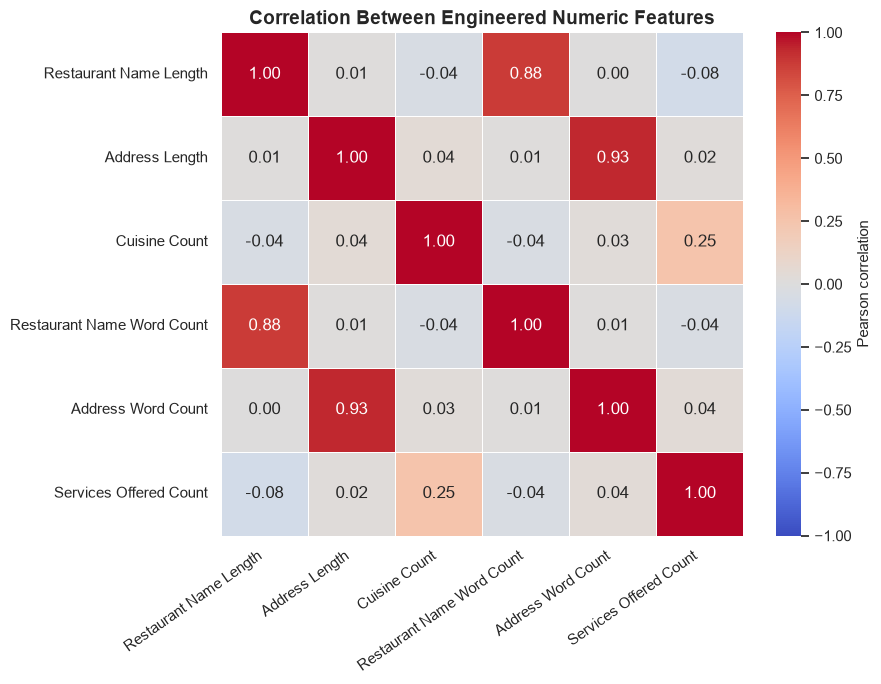

In [10]:
numeric_features = ["Restaurant Name Length", "Address Length", "Cuisine Count",
                    "Restaurant Name Word Count", "Address Word Count", "Services Offered Count"]
corr_matrix = engineered[numeric_features].astype(float).corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Correlation Between Engineered Numeric Features")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 8. Data Validation Checks
Each engineered feature is re-computed in a different way (plain Python loops) and compared with the pandas result. The checks also confirm that the original data was not changed. If any check fails, the notebook stops before exporting.

In [11]:
checks = []


def add_check(description, passed):
    checks.append({"Check": description, "Result": "PASS" if bool(passed) else "FAIL"})


original_columns = df.columns.tolist()

add_check("Row count unchanged", len(engineered) == len(df))
add_check("All original columns still present, in the same order", engineered.columns[:len(original_columns)].tolist() == original_columns)
add_check("Original column values unchanged", engineered[original_columns].equals(df))
add_check("No duplicate column names", not engineered.columns.duplicated().any())
add_check("All new feature columns exist", all(name in engineered.columns for name in new_features))

names = engineered["Restaurant Name"].tolist()
addresses = engineered["Address"].tolist()
add_check("Restaurant Name Length matches independent calculation",
          all((pd.isna(n) and pd.isna(l)) or len(str(n)) == l for n, l in zip(names, engineered["Restaurant Name Length"])))
add_check("Address Length matches independent calculation",
          all((pd.isna(a) and pd.isna(l)) or len(str(a)) == l for a, l in zip(addresses, engineered["Address Length"])))
add_check("Length features are never negative",
          (engineered["Restaurant Name Length"].dropna() >= 0).all() and (engineered["Address Length"].dropna() >= 0).all())

for source, feature in [("Has Table booking", "Has Table Booking"), ("Has Online delivery", "Has Online Delivery")]:
    values = set(engineered[feature].dropna().astype(int).unique())
    add_check(f"{feature} contains only 0 and 1 (plus missing)", values.issubset({0, 1}))
    cleaned = df[source].astype("string").str.strip().str.lower()
    add_check(f"{feature}: Yes -> 1 and No -> 0 are consistent with the source",
              (engineered.loc[cleaned == "yes", feature] == 1).all() and (engineered.loc[cleaned == "no", feature] == 0).all())
    unknown_mask = ~cleaned.isin(["yes", "no"]).fillna(False).astype(bool)
    add_check(f"{feature}: unknown source values stay missing (not 0)", engineered.loc[unknown_mask, feature].isna().all())

expected_cuisine = []
for value in df["Cuisines"]:
    if pd.isna(value):
        expected_cuisine.append(None)
        continue
    parts = {p.strip().lower() for p in str(value).split(",") if p.strip()}
    expected_cuisine.append(len(parts) if parts else None)
actual_cuisine = [None if pd.isna(v) else int(v) for v in engineered["Cuisine Count"]]
add_check("Cuisine Count matches independent calculation", expected_cuisine == actual_cuisine)
add_check("Cuisine Count is at least 1 wherever it is not missing", (engineered["Cuisine Count"].dropna() >= 1).all())
add_check("Cuisine Count missing only where Cuisines is missing/blank",
          engineered["Cuisine Count"].isna().sum() == (df["Cuisines"].isna() | df["Cuisines"].astype("string").str.strip().eq("").fillna(False)).sum())
add_check("Services Offered Count is between 0 and 2", engineered["Services Offered Count"].dropna().between(0, 2).all())
add_check("No leakage: no new feature name refers to rating, votes or colour",
          not any(word in name.lower() for name in new_features for word in ["rating", "votes", "color", "colour"]))

validation_table = pd.DataFrame(checks)
validation_table.index = validation_table.index + 1
validation_table.index.name = "#"
show_table(validation_table, "Validation results")

failed = validation_table[validation_table["Result"] == "FAIL"]
if len(failed):
    raise AssertionError(f"{len(failed)} validation check(s) failed - see the table above. Export cancelled.")
print(f"All {len(validation_table)} validation checks passed.")

**Validation results**

,Check,Result
#,,
1,Row count unchanged,PASS
2,"All original columns still present, in the sam...",PASS
3,Original column values unchanged,PASS
4,No duplicate column names,PASS
5,All new feature columns exist,PASS
6,Restaurant Name Length matches independent cal...,PASS
7,Address Length matches independent calculation,PASS
8,Length features are never negative,PASS
9,Has Table Booking contains only 0 and 1 (plus ...,PASS


All 19 validation checks passed.


## 9. Export the Engineered Dataset
The engineered data is saved to `../Dataset/engineered_restaurant_data.csv` **only when this cell is run**. The original `Dataset.csv` is never overwritten; the cell refuses to run if the two paths were ever the same. Missing values are written as empty cells.

In [12]:
OUTPUT_PATH = Path("../dataset/engineered_restaurant_data.csv")

if OUTPUT_PATH.resolve() == DATA_PATH.resolve():
    raise ValueError("Output path equals the original dataset path - refusing to overwrite Dataset.csv.")

engineered.to_csv(OUTPUT_PATH, index=False, encoding="utf-8")

check = pd.read_csv(OUTPUT_PATH, encoding="utf-8")
print(f"Saved: {OUTPUT_PATH}  ({OUTPUT_PATH.stat().st_size / 1024:,.0f} KB)")
print(f"Re-read check: {check.shape[0]:,} rows x {check.shape[1]} columns "
      f"(expected {engineered.shape[0]:,} x {engineered.shape[1]})")
assert check.shape == engineered.shape, "Exported file shape does not match the engineered dataset."
print("Original Dataset.csv was not modified.")

Saved: ..\dataset\engineered_restaurant_data.csv  (2,402 KB)
Re-read check: 9,551 rows x 30 columns (expected 9,551 x 30)
Original Dataset.csv was not modified.


## 10. Key Findings
Generated by code from the engineered data.

In [26]:
findings = []

name_len = engineered["Restaurant Name Length"].astype(float)
addr_len = engineered["Address Length"].astype(float)
findings.append(
    f"**Name length:** restaurant names average {name_len.mean():.1f} characters (median {name_len.median():.0f}, "
    f"range {name_len.min():.0f}-{name_len.max():.0f})."
)
findings.append(
    f"**Address length:** addresses average {addr_len.mean():.1f} characters (median {addr_len.median():.0f}, "
    f"range {addr_len.min():.0f}-{addr_len.max():.0f}), about {addr_len.mean() / name_len.mean():.1f}x longer than names on average."
)

booking_share = engineered["Has Table Booking"].mean() * 100
delivery_share = engineered["Has Online Delivery"].mean() * 100
findings.append(
    f"**Services:** {booking_share:.1f}% of restaurants with a known value offer table booking and "
    f"{delivery_share:.1f}% offer online delivery."
)

cuisines = engineered["Cuisine Count"].dropna().astype(int)
modal_count = cuisines.mode().iloc[0]
findings.append(
    f"**Cuisines:** the most common Cuisine Count is {modal_count} ({(cuisines == modal_count).mean() * 100:.1f}% of restaurants with cuisine data); "
    f"the maximum is {cuisines.max()}. {engineered['Is Multi Cuisine'].mean() * 100:.1f}% list more than one cuisine."
)

pair_corr = corr_matrix.where(~np.eye(len(corr_matrix), dtype=bool)).abs()
strongest = pair_corr.stack().idxmax()
findings.append(
    f"**Correlation:** the strongest relationship between two engineered numeric features is "
    f"{strongest[0]} vs {strongest[1]} (r = {corr_matrix.loc[strongest[0], strongest[1]]:.2f})."
)

findings.append(
    f"**Missing values:** {int(engineered['Cuisine Count'].isna().sum()):,} restaurants have no cuisine information "
    f"(Cuisine Count left missing); {int(engineered['Has Table Booking'].isna().sum() + engineered['Has Online Delivery'].isna().sum()):,} "
    "Yes/No values were unknown (kept missing)."
)
findings.append(f"**Validation:** all {len(validation_table)} automatic checks passed, and the engineered file was exported to `{OUTPUT_PATH}`.")
show_findings(findings)

- **Name length:** restaurant names average 15.2 characters (median 14, range 2-54).
- **Address length:** addresses average 53.5 characters (median 52, range 13-132), about 3.5x longer than names on average.
- **Services:** 12.1% of restaurants with a known value offer table booking and 25.7% offer online delivery.
- **Cuisines:** the most common Cuisine Count is 2 (36.1% of restaurants with cuisine data); the maximum is 8. 64.4% list more than one cuisine.
- **Correlation:** the strongest relationship between two engineered numeric features is Address Length vs Address Word Count (r = 0.93).
- **Missing values:** 9 restaurants have no cuisine information (Cuisine Count left missing); 0 Yes/No values were unknown (kept missing).
- **Validation:** all 19 automatic checks passed, and the engineered file was exported to `..\Dataset\engineered_restaurant_data.csv`.

## 11. Conclusion
Feature engineering turned raw text and Yes/No columns into numeric features that statistical methods and machine-learning models can use directly. The new features describe a restaurant's naming and address style, how many cuisines it offers and which services it provides, while missing information is kept visible instead of being turned into misleading zeros. Because none of the features use rating, vote or colour columns, they can be used as inputs in later modelling work without leaking the outcome. The engineered dataset is saved separately as `engineered_restaurant_data.csv`, so the original data stays intact.